# UW–IBM QML Hackathon: Classical vs Projected Quantum Kernels

> 🆕 **Our notebook.** Cells from `# Start From Here` onward are IBM/UW's starter cells, reproduced **unchanged**. Everything marked **🆕 Our addition** is ours.
>
> Task: predict CAR T-cell cytotoxicity (binary) from 4 signaling-motif slots, comparing an RBF-SVM on classical one-hot features against an RBF-SVM on pre-computed quantum projections.


In [1]:
# 🆕 Our addition: confirm the kernel is the project environment
import sys, platform
print("Python:    ", sys.version.split()[0], "|", platform.system())
print("Executable:", sys.executable)


Python:     3.11.9 | Windows
Executable: c:\Users\bhara\Documents\hackathons\quantum-pqk-car-t-hackathon\qpqk-env\Scripts\python.exe


# Start From Here

Starter notebook for the UW–IBM Quantum Machine Learning Hackathon. Read the companion notebook `UW-IBM_QML_Hackathon.ipynb`to understand the hackathon objectives. This notebook handles environment setup, data preprocessing, and a quick baseline so you can hit the ground running:

1. Install + imports (Sections 1, 2)
2. Download + preprocess the CAR T-cell data (Section 3)
3. Quick baseline — classical vs. quantum-projected SVM with F1 comparison and kernel heatmaps (Section 4)
4. Pointer to the IBM PQK tutorial for Tracks 1, 2, and Bonus

After running every cell here, you'll have the same variables the IBM PQK tutorial expects from Step 2 onwards, plus a ΔF1 result you can sanity-check against the tutorial. From there you copy cells from the tutorial to build out your own analyses for the hackathon prompt's challenge tracks.

## 1. Environment Setup

### Install required packages

Run this once per environment. If you're on Colab or a fresh JupyterLab session, this will take ~2 minutes. If everything is already installed, pip will skip ahead.

In [2]:
!pip install -U "qiskit[visualization]" qiskit-ibm-runtime \
    category-encoders==2.8.1 numpy==2.3.2 pandas==2.3.2 \
    scikit-learn tqdm==4.67.1

### Import libraries

All imports for the whole notebook live in this single cell. If you run a later cell and get a `NameError`, come back and re-run this one.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold, StratifiedShuffleSplit
from sklearn.metrics import f1_score, classification_report
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

from scipy.linalg import inv, sqrtm

# Qiskit (only needed for Track 2D real-hardware comparison)
from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import (
    Batch,
    EstimatorOptions,
    EstimatorV2 as Estimator,
    QiskitRuntimeService,
)

import tqdm

# Global random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. IBM Quantum Account Setup

> **Team account**
>
> For this hackathon you'll use a shared **team account** with 25 minutes of QPU time. To access it you need an API key which you received today.
>
> If your team runs out of QPU time, contact your IBM mentor (Sophy) or a UW admin (Kristen)

> **⚠️ Back up your results before May 16, 2026 ⚠️**
>
> The hackathon team accounts will be deleted on May 16th, 2026. Save your job results to disk before then — see [Retrieve job results](https://quantum.cloud.ibm.com/docs/en/guides/save-jobs#retrieve-job-results-from-ibm-quantum) and [Save results to disk](https://quantum.cloud.ibm.com/docs/en/guides/save-jobs#save-results-to-disk).

### Enter your credentials

Replace the placeholders below with your team's API key and CRN.

In [4]:
API_KEY = "YOUR_API_KEY_HERE"

# Uncomment to save credentials once (then comment back out):
# QiskitRuntimeService.save_account(
#     token=API_KEY,
#     overwrite=True,
# )

# Uncomment to load and verify your service connection:
# service = QiskitRuntimeService(token=API_KEY)
# print("Available backends:", [b.name for b in service.backends()])

In [5]:
#service = QiskitRuntimeService(token=api, instance=crn_open)
service= QiskitRuntimeService()
print("Available backends:", [b.name for b in service.backends()])

InvalidAccountError: 'Unable to retrieve instances. Please check that you are using a valid API token.'

## 3. Download and preprocess the CAR T-cell data

The dataset is hosted in the official Qiskit documentation repo. We download four files:

- `train_data.csv`, `test_data.csv` — raw motif IDs and cytotoxicity scores
- `projections_train.csv`, `projections_test.csv` — pre-computed 180-dim quantum projections from IBM Heron R2 hardware

After downloading, we sanitize the files if needed (some shipped versions have a UTF-8 BOM and wrapped quotes), then preprocess them using the **exact pipeline from the IBM PQK tutorial** — same `preprocess_data` / `data_encoder` functions, same `args` dict, same π/2 scaling — so your numbers align with the paper (Utro et al. 2025) and the official tutorial.

In [6]:
def download_pqk_dataset(data_dir="data_tutorial/pqk"):
    """Download the four CSV files from the Qiskit documentation repo."""
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)

    base_url = (
        "https://raw.githubusercontent.com/Qiskit/documentation/main/"
        "datasets/tutorials/pqk"
    )
    files = [
        "train_data.csv",
        "test_data.csv",
        "projections_train.csv",
        "projections_test.csv",
    ]

    for filename in files:
        url = f"{base_url}/{filename}"
        dest = data_dir / filename
        print(f"  {filename} ...", end=" ", flush=True)
        urllib.request.urlretrieve(url, dest)
        print(f"✓ ({dest.stat().st_size:,} bytes)")

    print(f"\nAll files saved to {data_dir}/")
    return data_dir


DATA_DIR = download_pqk_dataset()

  train_data.csv ... ✓ (5,012 bytes)
  test_data.csv ... ✓ (2,194 bytes)
  projections_train.csv ... ✓ (779,730 bytes)
  projections_test.csv ... ✓ (335,529 bytes)

All files saved to data_tutorial\pqk/


In [7]:
# ---------------------------------------------------------------------------
# Helper: sanitize CSV files into well-formed ones.
#
# The data files in this dataset sometimes ship with two quirks that confuse pd.read_csv:
#   - a UTF-8 BOM at the start
#   - every line wrapped in an extra pair of double quotes, so the whole row is parsed as one column of 172/74 strings (motif CSVs only)
#   - whitespace-separated floats instead of commas (projection CSVs only)
#
# We detect and repair these in place so the IBM tutorial code below works unmodified. Already well-formed files are left alone.
# ---------------------------------------------------------------------------
def sanitize_csv_files(data_dir):
    """Normalize quirky CSV files to well-formed UTF-8 comma-separated CSVs."""
    data_dir = Path(data_dir)

    # Motif files: strip BOM and outer line-wrap quotes if present.
    for name in ["train_data.csv", "test_data.csv"]:
        path = data_dir / name
        if not path.exists():
            continue
        with open(path, "rb") as f:
            raw = f.read()
        text = raw.decode("utf-8-sig")
        lines = text.replace("\r\n", "\n").strip().split("\n")
        wrapped = all(
            len(L) >= 2 and L.startswith('"') and L.endswith('"') for L in lines
        )
        if wrapped:
            lines = [L[1:-1] for L in lines]
        cleaned = "\n".join(lines) + "\n"
        if cleaned.encode("utf-8") != raw:
            path.write_text(cleaned, encoding="utf-8")
            print(f"  Sanitized {name}")

    # Projection files: convert whitespace-separated to comma-separated if needed.
    for name in ["projections_train.csv", "projections_test.csv"]:
        path = data_dir / name
        if not path.exists():
            continue
        with open(path, "rb") as f:
            head = f.read(2048)
        text_head = head.decode("utf-8-sig", errors="replace")
        first_line = text_head.split("\n")[0]
        # If the first line has many whitespace-separated floats and no commas,
        # it\'s the whitespace-separated format.
        if "," not in first_line and len(first_line.split()) > 10:
            # Whitespace-separated → reload with pandas sep=r"\s+" and rewrite as CSV.
            from io import StringIO
            with open(path, "rb") as f:
                text = f.read().decode("utf-8-sig")
            df = pd.read_csv(StringIO(text), sep=r"\s+", header=None, engine="python")
            df.to_csv(path, index=False, header=False)
            print(f"  Sanitized {name}")


sanitize_csv_files(DATA_DIR)


# ---------------------------------------------------------------------------
# The two preprocessing functions below are the IBM PQK tutorial code, 
# kept intentionally close to the original so your results align with the paper (Utro et al. 2025) and the tutorial. See:
#   https://quantum.cloud.ibm.com/docs/en/tutorials/projected-quantum-kernels
# ---------------------------------------------------------------------------
def preprocess_data(dir_root, args):
    """
    Preprocess the training and test data.
    Tutorial-exact: load CSVs, normalize motif ID 17 → 14, force canonical
    column names, optionally filter by spacer-motif rules, binarize labels
    at the cytotoxicity threshold, shift motif IDs to start at 0.
    """
    # Read from the csv files
    train_data = pd.read_csv(
        os.path.join(dir_root, args["file_train_data"]),
        encoding="unicode_escape",
        sep=",",
    )
    test_data = pd.read_csv(
        os.path.join(dir_root, args["file_test_data"]),
        encoding="unicode_escape",
        sep=",",
    )

    # Fix the last motif ID
    train_data[train_data == 17] = 14
    train_data.columns = [
        "Cell Number",
        "motif",
        "motif.1",
        "motif.2",
        "motif.3",
        "motif.4",
        "Nalm 6 Cytotoxicity",
    ]
    test_data[test_data == 17] = 14
    test_data.columns = [
        "Cell Number",
        "motif",
        "motif.1",
        "motif.2",
        "motif.3",
        "motif.4",
        "Nalm 6 Cytotoxicity",
    ]

    # Adjust motif at the third position
    if args["filter_for_spacer_motif_third_position"]:
        train_data = train_data[
            (train_data["motif.2"] == 14) | (train_data["motif.2"] == 0)
        ]
        test_data = test_data[
            (test_data["motif.2"] == 14) | (test_data["motif.2"] == 0)
        ]

    train_data = train_data[
        args["motifs_to_use"] + [args["label_name"], "Cell Number"]
    ]
    test_data = test_data[
        args["motifs_to_use"] + [args["label_name"], "Cell Number"]
    ]

    # Adjust motif at the last position
    if not args["allow_spacer_motif_last_position"]:
        last_motif = args["motifs_to_use"][len(args["motifs_to_use"]) - 1]
        train_data = train_data[
            (train_data[last_motif] != 14) & (train_data[last_motif] != 0)
        ]
        test_data = test_data[
            (test_data[last_motif] != 14) & (test_data[last_motif] != 0)
        ]

    # Get the labels
    train_labels = np.array(train_data[args["label_name"]])
    test_labels = np.array(test_data[args["label_name"]])

    # For the classification task use the threshold to binarize labels
    train_labels[train_labels > args["label_binarization_threshold"]] = 1
    train_labels[train_labels < 1] = args["min_label_value"]
    test_labels[test_labels > args["label_binarization_threshold"]] = 1
    test_labels[test_labels < 1] = args["min_label_value"]

    # Reduce data to just the motifs of interest
    train_data = train_data[args["motifs_to_use"]]
    test_data = test_data[args["motifs_to_use"]]

    # Get the class and motif counts
    min_class = np.min(np.unique(np.concatenate([train_data, test_data])))
    max_class = np.max(np.unique(np.concatenate([train_data, test_data])))

    num_class = max_class - min_class + 1
    num_motifs = len(args["motifs_to_use"])
    print(f"  max_class:min_class:num_class = {max_class}:{min_class}:{num_class}")
    print(f"  Train: {len(train_data)} samples, Test: {len(test_data)} samples")

    train_data = train_data - min_class
    test_data = test_data - min_class

    return (
        train_data,
        test_data,
        train_labels,
        test_labels,
        num_class,
        num_motifs,
    )


def data_encoder(args, train_data, test_data, num_class, num_motifs):
    """
    Use one-hot or binary encoding for classical data representation.
    Tutorial-exact.
    """
    if args["encoder"] == "one-hot":
        train_data = np.eye(num_class)[train_data]
        test_data = np.eye(num_class)[test_data]

        train_data = train_data.reshape(
            train_data.shape[0], train_data.shape[1] * train_data.shape[2]
        )
        test_data = test_data.reshape(
            test_data.shape[0], test_data.shape[1] * test_data.shape[2]
        )

    elif args["encoder"] == "binary":
        import category_encoders as ce
        encoder = ce.BinaryEncoder()
        base_array = np.unique(np.concatenate([train_data, test_data]))
        base = pd.DataFrame(base_array).astype("category")
        base.columns = ["motif"]
        for motif_name in args["motifs_to_use"][1:]:
            base[motif_name] = base.loc[:, "motif"]
        encoder.fit(base)

        train_data = encoder.transform(train_data.astype("category"))
        test_data = encoder.transform(test_data.astype("category"))

        train_data = np.reshape(
            train_data.values, (train_data.shape[0], num_motifs, -1)
        )
        test_data = np.reshape(
            test_data.values, (test_data.shape[0], num_motifs, -1)
        )

        train_data = train_data.reshape(
            train_data.shape[0], train_data.shape[1] * train_data.shape[2]
        )
        test_data = test_data.reshape(
            test_data.shape[0], test_data.shape[1] * test_data.shape[2]
        )

    else:
        raise ValueError("Invalid encoding type.")

    return train_data, test_data


# ---------------------------------------------------------------------------
# Run preprocessing using the tutorial's exact args.
# ---------------------------------------------------------------------------
args = {
    "file_train_data": "train_data.csv",
    "file_test_data": "test_data.csv",
    "motifs_to_use": ["motif", "motif.1", "motif.2", "motif.3"],
    "label_name": "Nalm 6 Cytotoxicity",
    "label_binarization_threshold": 0.62,
    "filter_for_spacer_motif_third_position": False,
    "allow_spacer_motif_last_position": True,
    "min_label_value": -1,
    "encoder": "one-hot",
}

# preprocess_data returns motif-ID DataFrames; we keep these around for Track 2C.
train_motifs, test_motifs, train_labels, test_labels, num_class, num_motifs = (
    preprocess_data(dir_root=str(DATA_DIR), args=args)
)
NUM_CLASS = int(num_class)
NUM_MOTIFS = int(num_motifs)

# data_encoder turns motif IDs into one-hot vectors.
train_data, test_data = data_encoder(args, train_motifs, test_motifs, num_class, num_motifs)

# Tutorial step: scale the active one-hot entries to π/2.
angle = np.pi / 2
tmp = pd.DataFrame(train_data).astype("float64"); tmp[tmp == 1] = angle
train_data = tmp.values
tmp = pd.DataFrame(test_data).astype("float64"); tmp[tmp == 1] = angle
test_data = tmp.values

print(f"  train_data: {train_data.shape}")
print(f"  test_data:  {test_data.shape}")

  Sanitized projections_train.csv
  Sanitized projections_test.csv
  max_class:min_class:num_class = 14:0:15
  Train: 172 samples, Test: 74 samples
  train_data: (172, 60)
  test_data:  (74, 60)


### Load the pre-computed quantum projections

The IBM PQK tutorial spends roughly 80 minutes of QPU time generating the 180-dim projections. We use the pre-computed CSVs that shipped with the tutorial repo, so you can skip directly to analysis.

After this cell runs, you'll have all the variables the IBM tutorial expects from Step 2 onwards:

| Variable | Shape | Source |
|---|---|---|
| `train_data` | `(172, 60)` | One-hot motifs × π/2 |
| `test_data` | `(74, 60)` | Same encoding |
| `train_labels` | `(172,)` | Binary {−1, +1} |
| `test_labels` | `(74,)` | Same |
| `projections_train` | `(172, 180)` | Pre-computed quantum 1-RDMs |
| `projections_test` | `(74, 180)` | Same |
| `num_class` | `15` | Number of motif IDs |
| `num_motifs` | `4` | Number of motif positions |

If you want to generate your own projections on a real QPU as part of the hackathon, follow the tutorial's Step 3 ("Execute using Qiskit primitives"). You'll need an active IBM Quantum account and ~80 minutes of queue + execution time on a Heron-class backend.

In [8]:
# Load the pre-computed 180-dim quantum projections.
# Headers may or may not be present depending on which version of the file
# you have; we read with header=0 first and detect the no-header case by
# checking that the first row is numeric.
def _load_projections(path):
    df = pd.read_csv(path)
    # If the header row turned out to be data (first column not parseable as
    # column-name-like), reload without a header.
    try:
        _ = df.columns.astype(float)
        df = pd.read_csv(path, header=None)
    except (ValueError, TypeError):
        pass
    df.columns = [f"q{i}" for i in range(df.shape[1])]
    return df


projections_train = _load_projections(DATA_DIR / "projections_train.csv")
projections_test = _load_projections(DATA_DIR / "projections_test.csv")

# Sanity check — all four feature matrices and the label arrays must agree.
assert len(train_data) == len(projections_train) == len(train_labels), (
    f"Train length mismatch: train_data={len(train_data)}, "
    f"projections_train={len(projections_train)}, labels={len(train_labels)}"
)
assert len(test_data) == len(projections_test) == len(test_labels), (
    f"Test length mismatch: test_data={len(test_data)}, "
    f"projections_test={len(projections_test)}, labels={len(test_labels)}"
)

print(f"train_data:        {train_data.shape},   test_data:        {test_data.shape}")
print(f"projections_train: {projections_train.shape}, projections_test: {projections_test.shape}")
print(f"train_labels:      {train_labels.shape},        test_labels:      {test_labels.shape}")
print(f"Class balance (train): {dict(zip(*np.unique(train_labels, return_counts=True)))}")
print(f"Class balance (test):  {dict(zip(*np.unique(test_labels, return_counts=True)))}")


train_data:        (172, 60),   test_data:        (74, 60)
projections_train: (172, 180), projections_test: (74, 180)
train_labels:      (172,),        test_labels:      (74,)
Class balance (train): {np.float64(-1.0): np.int64(83), np.float64(1.0): np.int64(89)}
Class balance (test):  {np.float64(-1.0): np.int64(35), np.float64(1.0): np.int64(39)}


## 4. Quick baseline

This section trains a classical and a quantum-projected RBF-SVM on the data you just loaded and compares them. It uses the same hyperparameter grid as the IBM PQK tutorial (13 × 12 = 156 grid points, 10-fold CV) so your numbers will match the tutorial's headline result.

Runtime: ~1–2 minutes on a modern laptop.

After this you have the **Track 0 baseline result** plus two visuals to look at, and you can move on to designing your own Track 0 / 1 / 2 / Bonus experiments by copying cells from the tutorial.

In [9]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, classification_report

# Hyperparameter grid matched to the IBM PQK tutorial scale.
# 13 C values × 12 γ values = 156 grid points, 10-fold CV.
PARAM_GRID = {
    "C":     [0.1, 0.5, 1, 2.5, 5, 7.5, 8.5, 10, 10.75, 15, 25, 50, 100],
    "gamma": ["auto", "scale", 0.001, 0.005, 0.01, 0.02, 0.04, 0.05,
              0.1, 0.25, 0.5, 1],
}
cv = StratifiedKFold(n_splits=10)

# Classical SVM on raw one-hot features
print("Training classical SVM (~30s)...")
svm_classical = GridSearchCV(
    SVC(kernel="rbf"), PARAM_GRID, cv=cv,
    scoring="f1_weighted", n_jobs=-1,
).fit(train_data, train_labels)
pred_classical = svm_classical.predict(test_data)
f1_classical = f1_score(test_labels, pred_classical, average="weighted")

# Quantum-projected SVM on the pre-computed 180-dim projections
print("Training quantum-projected SVM (~30s)...")
svm_quantum = GridSearchCV(
    SVC(kernel="rbf"), PARAM_GRID, cv=cv,
    scoring="f1_weighted", n_jobs=-1,
).fit(projections_train, train_labels)
pred_quantum = svm_quantum.predict(projections_test)
f1_quantum = f1_score(test_labels, pred_quantum, average="weighted")

print()
print(f"Classical: best params = {svm_classical.best_params_}, test F1 = {f1_classical:.4f}")
print(f"Quantum:   best params = {svm_quantum.best_params_}, test F1 = {f1_quantum:.4f}")
print(f"ΔF1 (quantum − classical) = {f1_quantum - f1_classical:+.4f}")


Training classical SVM (~30s)...
Training quantum-projected SVM (~30s)...

Classical: best params = {'C': 10.75, 'gamma': 0.04}, test F1 = 0.7423
Quantum:   best params = {'C': 8.5, 'gamma': 0.01}, test F1 = 0.8108
ΔF1 (quantum − classical) = +0.0686


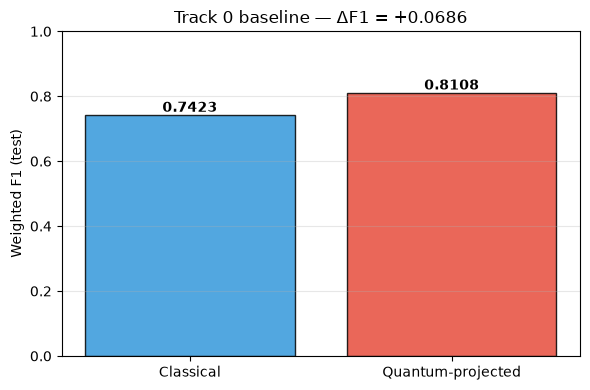

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Classical", "Quantum-projected"],
    [f1_classical, f1_quantum],
    color=["#3498db", "#e74c3c"], alpha=0.85, edgecolor="black",
)
for b, score in zip(bars, [f1_classical, f1_quantum]):
    ax.text(b.get_x() + b.get_width() / 2, score + 0.01,
            f"{score:.4f}", ha="center", fontweight="bold")
ax.set_ylabel("Weighted F1 (test)")
ax.set_ylim(0, 1)
ax.set_title(f"Track 0 baseline — ΔF1 = {f1_quantum - f1_classical:+.4f}")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


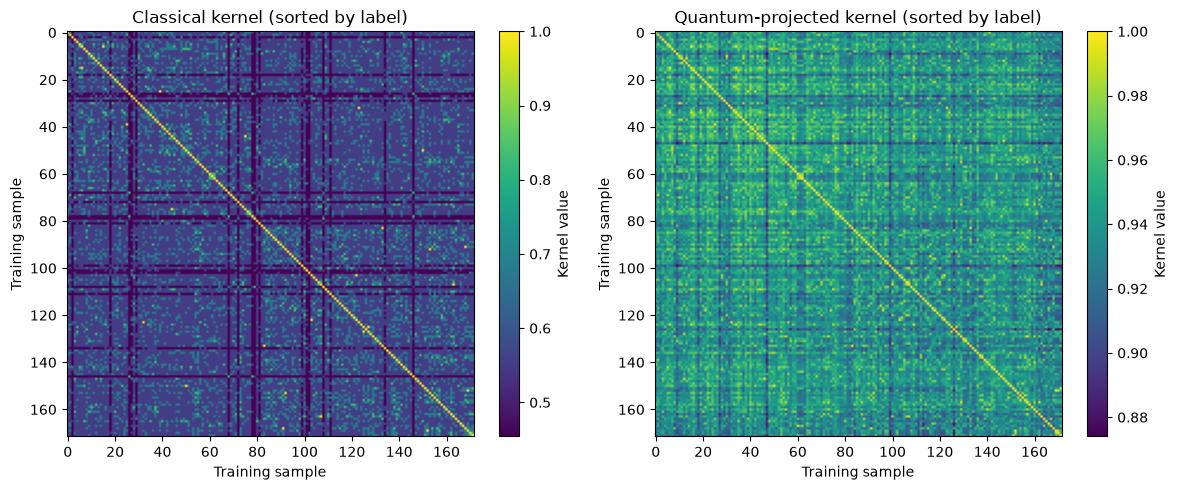

Look for block-diagonal structure (high within-class similarity). Which kernel shows it more clearly?


In [11]:
from sklearn.metrics.pairwise import rbf_kernel


def resolve_gamma(gamma, X):
    """Convert sklearn's 'scale'/'auto' strings to a numeric γ for rbf_kernel."""
    Xarr = np.asarray(X)
    if gamma == "scale":
        return 1.0 / (Xarr.shape[1] * Xarr.var())
    if gamma == "auto":
        return 1.0 / Xarr.shape[1]
    return gamma


gamma_c = resolve_gamma(svm_classical.best_params_["gamma"], train_data)
gamma_q = resolve_gamma(svm_quantum.best_params_["gamma"], projections_train)

K_c = rbf_kernel(train_data, gamma=gamma_c)
K_q = rbf_kernel(projections_train, gamma=gamma_q)

# Sort rows and columns by label to make any class structure visible
sort_idx = np.argsort(train_labels)
K_c_sorted = K_c[sort_idx][:, sort_idx]
K_q_sorted = K_q[sort_idx][:, sort_idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, K, title in zip(
    axes,
    [K_c_sorted, K_q_sorted],
    ["Classical kernel (sorted by label)",
     "Quantum-projected kernel (sorted by label)"],
):
    im = ax.imshow(K, cmap="viridis", aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Training sample")
    ax.set_ylabel("Training sample")
    plt.colorbar(im, ax=ax, label="Kernel value")
plt.tight_layout()
plt.show()

print("Look for block-diagonal structure (high within-class similarity)."
      " Which kernel shows it more clearly?")


## You're ready — continue from the IBM PQK tutorial

You now have a working baseline (the section above). To go further on Tracks 1 (Anatomy), 2 (Robustness), or Bonus (geometric difference), open the IBM PQK tutorial notebook (`projected-quantum-kernels.ipynb`) and copy cells into this notebook (or a scratch notebook in the same kernel session).

### Which tutorial cells to copy, and which to SKIP

The tutorial mixes "explain how to compute the projections" with "use the pre-computed projections". You already have the projections — you should **skip the cells that re-compute them**. Here's a precise guide:

| Tutorial cell | Content | What to do |
|---|---|---|
| **Cell 20** | `feature_dimension = train_data.shape[1]` + ZZFeatureMap embedding | Copy if you want to use the ZZ feature map |
| **Cell 22** | Same as 20 but with 1D-Heisenberg Hamiltonian embedding | Copy (optional, alternative embedding) |
| **Cells 27, 29, 31, 32, 34** | Backend selection, single-sample QPU smoke test | Skip unless you want to verify QPU access |
| **Cells 37–44** | Loop over all 172 training samples on QPU (~80 min) | Skip — these regenerate the projections we already loaded |
| **Cell 51** | `projections_train = np.loadtxt("projections_train.txt")` | SKIP — will fail. This loads cached `.txt` files that don't ship with the dataset; we already loaded the `.csv` versions above into `projections_train` and `projections_test`. |
| **Cells 54, 56** | Train classical + quantum SVMs with GridSearchCV | ✅ Copy — this is your Track 0 baseline |
| **Cells 59, 61, 62** | Geometric difference $g$ + model complexities | ✅ Copy — this is the Bonus track |

### For Tracks 1 and 2 (Anatomy / Robustness)

Design your own slicing and subsetting code on top of `projections_train`, `projections_test`, `train_data`, `test_data`, and the motif metadata in `train_motifs`, `test_motifs`. Useful slicing patterns:

```python
# By measurement basis — projections_train is laid out as <X> | <Y> | <Z>
basis_X = projections_train.iloc[:, 0:60]      # ⟨X⟩ on 60 qubits
basis_Y = projections_train.iloc[:, 60:120]    # ⟨Y⟩
basis_Z = projections_train.iloc[:, 120:180]   # ⟨Z⟩

# By motif position — every 15-column block within each basis
# (position 1 = cols 0-14, position 2 = cols 15-29, etc., per basis)
```

For the problem statement, hypotheses, and presentation requirements, see the companion `UW-IBM_QML_Hackathon.ipynb` prompt notebook.